Работу выполняли: Шамаев Климент Александрович, Волченков Арсений Максимович, Барыкина Людмила Артемовна

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
waves=['s','t','u','v', 'w', 'x', 'y', 'z', 'aa', 'bb'] #массив уникальных индексов волн

In [ ]:
# Если необходимо, установите библиотеку pyreadstat:
! pip install pyreadstat
import pyreadstat as pt

# Задание №0: Загрузка и предварительная обработка данных

1. Загрузите данные RLMS (например, в формате .sav) с официального источника [RLMS](https://hse.ru/rlms).

2. Выполните очистку и гармонизацию данных:
- Приведение имён столбцов к нижнему регистру и удаление лишних пробелов.
- Обработка пропусков и рекодирование категориальных переменных.
- Объединение домохозяйственных и индивидуальных анкет (используйте переменные вида `bbidindX`).

В папках Households и Individuals мы сохраняли данные по домохозяйствам и индивидам соответственно всех требуемых лет (на каждый год по два датасета, с официального сайта RLMS)

In [ ]:
# Создаем пустой список для хранения датафреймов
dfs = []

# Проходим по волнам
for i in range(23, 33):
    # Получаем текущую волну
    ch = waves[i - 23]

    """Загрузка датасета для индивидов"""
    try:
        # Пытаемся загрузить .sav файл для текущей волны с суффиксом 73
        df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_73.sav")
    except:
        try:
            # Если не получилось, пробуем суффикс 74
            df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_74.sav")
        except:
            try:
                # Если снова не получилось, пробуем суффикс 75
                df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_75.sav")
            except Exception as e:
                # Если все попытки неудачны, выводим ошибку
                print(f"Ошибка загрузки: {e}")

    # Создаем словарь с данными из загруженного датафрейма df_i
    data = {
        "wave": [ch] * len(df_i),  # Волна (одинаковая для всех строк)
        "num_child": df_i[f"{ch}j72.172"],  # Количество детей
        "id_h": df_i[f"{ch}id_h"],  # ID домохозяйства
        "married": df_i[f"{ch}j322"],  # Семейное положение
        "life_satisfaction": df_i[f"{ch}j65"],  # Удовлетворенность жизнью
        "religion": df_i[f"{ch}j72.18"],  # Религия
        "status": df_i["status"],  # Статус (из исходного датафрейма)
        "popul": df_i["popul"],  # Население (из исходного датафрейма)
        "redid_i": df_i["redid_i"]
    }

    # Преобразуем словарь в датафрейм
    df_i = pd.DataFrame(data)

    """Загрузка датасета для домохозяйств"""
    try:
        # Пытаемся загрузить .sav файл для текущей волны с суффиксом 71
        df_h, _ = pt.read_sav(f"/content/Households/r{i}h_os_71.sav")
    except:
        try:
            # Если не получилось, пробуем суффикс 61
            df_h, _ = pt.read_sav(f"/content/Households/r{i}h_os_61.sav")
        except Exception as e:
            # Если все попытки неудачны, выводим ошибку
            print(f"Ошибка загрузки: {e}")

    # Создаем словарь с данными из загруженного датафрейма df_h
    data = {
        "redid_h": df_h[f"{ch}redid_h"],  # Уникальный ID домохозяйства
        "id_h": df_h[f"{ch}id_h"],  # ID домохозяйства (для связи с df_i)
        "income": df_h[f"{ch}f14"],  # Доход домохозяйства
    }

    # Преобразуем словарь в датафрейм
    df_h = pd.DataFrame(data)

    # Объединяем датафреймы домохозяйств и индивидов по полю id_h
    data = pd.merge(df_h, df_i, on="id_h", how="inner")

    # Добавляем объединенный датафрейм в список dfs
    dfs.append(data)

# Объединяем все датафреймы из списка dfs в один большой датафрейм
rlms_df = pd.concat(dfs, axis=0, ignore_index=True)

print(rlms_df)


KeyError: 'redid_i'

Вспомогательная функция для анализа данных:

In [ ]:
def harmonize_data(data):
    """Функция для предварительной обработки и гармонизации данных RLMS."""
    # Создаем копию входных данных, чтобы не изменять оригинальный DataFrame
    df = data.copy()
    # Нормализация названий столбцов: удаление пробелов и приведение к нижнему регистру
    df = df.rename(columns=lambda x: x.strip().lower())

    # Обработка пропущенных значений и выбросов в количестве детей
    df = df.dropna(
        subset=["num_child"]
    )  # Удаляем строки с пропусками в количестве детей
    df = df.drop(
        df[df["num_child"] > 9000].index
    )  # Удаляем нереалистичные значения (>9000)

    # Словари для преобразования кодированных значений в понятные категории
    status_map = {  # Тип населенного пункта
        1: "Областной центр",
        2: "Город",
        3: "ПГТ",
        4: "Село",
    }

    wave_to_year = {  # Соответствие волн исследования годам
        "s": 2014,
        "t": 2015,
        "u": 2016,
        "v": 2017,
        "w": 2018,
        "x": 2019,
        "y": 2020,
        "z": 2021,
        "aa": 2022,
        "bb": 2023,
    }

    # Применяем преобразования к данным
    df["status"] = df["status"].map(status_map)  # Тип населенного пункта
    df["redid_h"] = df["redid_h"].astype(
        int
    )  # Приводим ID домохозяйства к целому числу

    # Категоризация религии
    df["religion"] = df["religion"].apply(
        lambda x: (
            "Верующий"
            if x in [1, 2]
            else "Неверующий" if x in [3, 4, 5] else "Нет репрезентативного ответа"
        )
    )

    # Категоризация удовлетворенности жизнью
    df["life_satisfaction"] = df["life_satisfaction"].apply(
        lambda x: (
            "Доволен"
            if x in [1, 2]
            else "Недоволен" if x in [4, 5] else "Нет репрезентативного ответа"
        )
    )

    # Категоризация семейного положения
    df["married"] = df["married"].apply(
        lambda x: (
            "Когда-либо был в браке"
            if x in [2, 3, 4, 5, 6]
            else (
                "Никогда не был в браке" if x in [1] else "Нет репрезентативного ответа"
            )
        )
    )

    # Преобразование волны исследования в год
    df["wave"] = df["wave"].map(wave_to_year).astype(int)

    # Дополнительные преобразования типов данных
    df["id_h"] = df["id_h"].astype(int)  # ID домохозяйства как целое число

    # Обработка выбросов в доходе (значения > 99999996 заменяем на 30000)
    df.loc[df["income"] > 99999996, "income"] = 30000

    # Приведение количества детей к целому числу
    df["num_child"] = df["num_child"].astype(int)

    # Выбираем одного члена домохозяйства с максимальным количеством детей
    # Это нужно для устранения дублирования данных по одному домохозяйству
    df = df.loc[df.groupby(["redid_h", "wave"])["num_child"].idxmax()]

    # Сортировка данных по году исследования и сброс индекса
    df = df.sort_values("wave").reset_index(drop=True)

    return df

In [ ]:
rlms_df_clear = harmonize_data(rlms_df)
rlms_df_clear.head()
print(rlms_df_clear)

       redid_h     id_h    income  wave  num_child                 married  \
0          663   720084   39500.0  2014          1  Когда-либо был в браке   
1          662   720083   59000.0  2014          1  Когда-либо был в браке   
2          661   720082   94000.0  2014          1  Когда-либо был в браке   
3          664   720085   35000.0  2014          1  Когда-либо был в браке   
4         6638   890115  155142.8  2014          1  Никогда не был в браке   
...        ...      ...       ...   ...        ...                     ...   
43560        3   580009   27500.0  2023          1  Когда-либо был в браке   
43561     4724  2000648   90000.0  2023          1  Когда-либо был в браке   
43562     4723  2000646   14500.0  2023          4  Когда-либо был в браке   
43563        4   580012   51000.0  2023          2  Когда-либо был в браке   
43564       12   580027   24500.0  2023          2  Когда-либо был в браке   

                  life_satisfaction    religion           statu

# Задание 3: Дети в динамике

В этом задании вам нужно изучить, как меняется жизнь россиян с появлением у них детей. Для этого вы будете использовать данные опроса RLMS за последние 10 доступных лет (с 2014 по 2023 гг.).

Данные RLMS имеют панельную структуру, то есть, каждый год организаторы исследования стараются опрашивать одних и тех же людей. Это позволяет изучать не просто характеристики индивидов в данный год, но и их динамику, благодаря чему мы можем формулировать и проверять очень нетривиальные гипотезы. Для того, чтобы найти данного человека в опроснике за другой год, вы можете воспользоваться переменной «idind» или переменными вида «**X**id_i» (для ID индивида), «**X**id_h» (для ID его домохозяйства), где X – номер волны опроса. Случается так, что индивиды перестают участвовать в опросе (и тогда организаторы находят новых участников), в этом случае для них не получится найти данные за последующие годы, а для вновь добавленных в исследование респондентов – их предысторию. Это важный момент, который стоит учитывать.

Для того, чтобы понять родственные связи членов домохозяйства, мы будем использовать переменные из опросника по домохозяйствам вида «bbb**X**.9.**Y**»,  где X и Y – номера членов домохозяйства. Из этих показателей несложно восстановить полную структуру семьи.

Для того, чтобы подтянуть к характеристикам домохозяйства данные по отдельным его членам, вы можете использовать переменные вида «bbidind**X**», (где X – номер члена домохозяйства): в них находятся идентификационные номера членов семьи, по которым их можно найти в опроснике по индивидам.

### 3.1 Определение семей с появлением детей

Начнём с простого: найдём все семьи, в которых за эти 10 лет появились дети. Эти семьи не обязательно должны входить в исследование во все 10 волн, но нам нужно, чтобы по ним были данные до появления ребёнка и после. Ребёнок не обязательно должен быть первым (поэтому, к примеру, переменную о наличии детей «bbj72.171» мы использовать не можем. А переменную о количестве детей – можем!).

Посчитайте долю семей, в которых появились дети, в зависимости от того, в городе живёт семья или в сельской местности и в зависимости от численности населения населённого пункта. Визуализируйте эти результаты на графике.

In [ ]:
children = dict()  # Словарь: номер - количество детей
answer = set()  # Номера семей, где родился ребёнок
ids = set()  # Множество всех семей


def identify_new_children_families(df):
    """Функция для идентификации семей, в которых появились новые дети."""
    for _, row in df.iterrows():  # Итерация по строкам DataFrame
        # Добавляем идентификатор семьи в множество всех семей
        ids.add(row["redid_h"])

        # Проверяем, есть ли уже запись о количестве детей в этой семье
        if row["redid_h"] in children.keys():
            # Если текущее количество детей больше сохраненного,
            # значит в семье появился новый ребенок
            if row["num_child"] > children[row["redid_h"]]:
                # Добавляем семью в множество семей с новыми детьми
                answer.add(row["redid_h"])
                # Обновляем максимальное количество детей для этой семьи
                children[row["redid_h"]] = row["num_child"]
        else:
            # Если это первая запись о семье, сохраняем количество детей
            children[row["redid_h"]] = row["num_child"]


# Создаем копию исходного DataFrame для работы
rlms_panel_df = rlms_df_clear.copy()

# Вызываем функцию для идентификации семей с новыми детьми
identify_new_children_families(rlms_panel_df)

print("Количество семей, в которых родился ребёнок:", len(answer))
print("Всего семей:", len(ids))

Количество семей, в которых родился ребёнок: 4465
Всего семей: 7426


In [ ]:
# Сохраняем в датасет последнюю информацию о каждой семье
# Создаем пустой DataFrame для финального набора данных
rlms_final = pd.DataFrame(
    {
        "wave": [],  # Волна исследования
        "redid_h": [],  # Уникальный идентификатор домохозяйства
        "num_child": [],  # Количество детей в семье
        "born_child": [],  # Флаг (0/1) - появился ли новый ребенок
        "married": [],  # Семейное положение
        "status": [],  # Тип населенного пункта
        "popul": [],  # Размер населенного пункта
        "life_satisfaction": [],  # Удовлетворенность жизнью
        "religion": [],  # Религиозная принадлежность
    }
)

# Множество для отслеживания уже обработанных домохозяйств
used_ids = set()

# Итерируемся по данным в обратном порядке (от последних наблюдений к первым)
# Это позволяет сохранять последнюю доступную информацию о каждом домохозяйстве
for i, row in rlms_df_clear[::-1].iterrows():
    # Проверяем, не обрабатывали ли мы уже это домохозяйство
    if row["redid_h"] not in used_ids:
        # Добавляем новую строку в финальный DataFrame
        rlms_final.loc[len(rlms_final)] = [
            row["wave"],  # Год исследования
            row["redid_h"],  # ID домохозяйства
            row["num_child"],  # Количество детей
            int(row["redid_h"] in answer),  # 1 если в семье появился ребенок, иначе 0
            row["married"],  # Семейное положение
            row["status"],  # Тип населенного пункта
            row["popul"],  # Размер населенного пункта
            row["life_satisfaction"],  # Удовлетворенность жизнью
            row["religion"],  # Религия
        ]
        # Помечаем домохозяйство как обработанное
        used_ids.add(row["redid_h"])

# Переворачиваем DataFrame обратно (чтобы годы шли в хронологическом порядке)
rlms_final = rlms_final[::-1]

print(rlms_final)

      wave  redid_h  num_child  born_child                 married  \
7425  2015     9529          2           0  Когда-либо был в браке   
7424  2015     9526          2           0  Когда-либо был в браке   
7423  2015     9525          1           0  Когда-либо был в браке   
7422  2015     9524          2           0  Когда-либо был в браке   
7421  2015     9521          2           0  Когда-либо был в браке   
...    ...      ...        ...         ...                     ...   
4     2023        3          1           1  Когда-либо был в браке   
3     2023     4724          1           1  Когда-либо был в браке   
2     2023     4723          4           1  Когда-либо был в браке   
1     2023        4          2           1  Когда-либо был в браке   
0     2023       12          2           0  Когда-либо был в браке   

               status       popul             life_satisfaction    religion  
7425  Областной центр  12325400.0                       Доволен    Верующий  
742

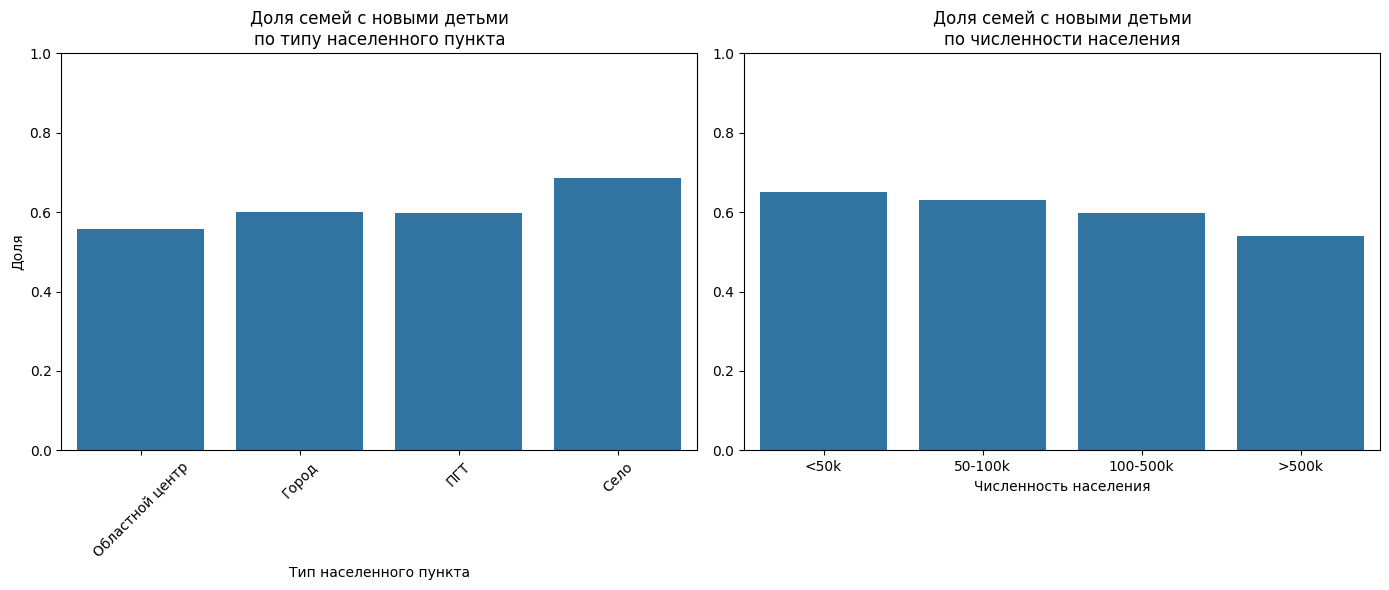

Общая доля семей с новыми детьми: 60.13%

Доля по типу населенного пункта:
            status     share
0            Город  0.599898
1  Областной центр  0.558118
2              ПГТ  0.597846
3             Село  0.685012

Доля по численности населения:
  population_group     share
0             <50k  0.649360
1          50-100k  0.630137
2         100-500k  0.598068
3            >500k  0.538742


In [ ]:
def calculate_new_children_share(data, answer, ids):
    """
    Рассчитывает долю семей с новыми детьми по группам:
    - тип населенного пункта (status)
    - численность населения (popul)
    """
    # Словарь для преобразования кодов статуса в названия
    status_labels = {
        1: 'Областной центр',
        2: 'Город',
        3: 'ПГТ',
        4: 'Село'
    }

    # 1. Статистика по типу населенного пункта
    loc_stats = (data.groupby('status')['born_child']
                 .mean()
                 .rename('share')
                 .reset_index())

    # 2. Статистика по численности населения
    # Определение границ и меток для категорий численности
    population_bins = [0, 50000, 100000, 500000, float('inf')]
    population_labels = ['<50k', '50-100k', '100-500k', '>500k']

    # Создание категориальной переменной для групп населения
    data['population_group'] = pd.cut(data['popul'],
                                     bins=population_bins,
                                     labels=population_labels)

    # Расчет доли по группам населения
    population_stats = (data.groupby('population_group', observed=False)['born_child']
                         .mean()
                         .rename('share')
                         .reset_index())

    # 3. Общая доля семей с новыми детьми
    total_share = data['born_child'].mean()

    return {
        'total': total_share,
        'location_type': loc_stats,
        'population': population_stats
    }

# Метки для групп населения (используются в визуализации)
population_labels = ['<50k', '50-100k', '100-500k', '>500k']

# Расчет статистик
stats = calculate_new_children_share(rlms_final.copy(), answer, ids)
new_children_share = stats['total']

# Визуализация
plt.figure(figsize=(14, 6))

#Тип населенного пункта
plt.subplot(1, 2, 1)
sns.barplot(data=stats['location_type'], x='status', y='share',
            order=['Областной центр', 'Город', 'ПГТ', 'Село'])
plt.title('Доля семей с новыми детьми\nпо типу населенного пункта')
plt.xlabel('Тип населенного пункта')
plt.ylabel('Доля')
plt.xticks(rotation=45)
plt.ylim(0, 1)

#Численность населения
plt.subplot(1, 2, 2)
sns.barplot(data=stats['population'], x='population_group', y='share',
            order=population_labels)
plt.title('Доля семей с новыми детьми\nпо численности населения')
plt.xlabel('Численность населения')
plt.ylabel('')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()
print(f"Общая доля семей с новыми детьми: {new_children_share:.2%}")
print("\nДоля по типу населенного пункта:")
print(stats['location_type'])
print("\nДоля по численности населения:")
print(stats['population'])

### 3.2 Связь между доходом семьи и вероятностью рождения ребенка

Для каждой семьи (вне зависимости от наличия или отсутствия в ней детей) рассчитайте её суммарный доход. Сюда надо включить доход обоих родителей, бабушек-дедушек (если они проживают совместно с детьми и внуками), доход как трудовой от разных мест работы, так и пенсии и пособия. Обратите внимание, это несколько разных показателей, их можно найти, поискав по файлу опросника индивидов фразу «сколько денег».

Есть ли какая-то связь между доходом семьи и вероятностью появления в ней ребёнка в ближайший год? В ближайшие 3 года?

In [ ]:
def analyze_income_childbirth(df):
    """Анализирует вероятность рождения детей в зависимости от уровня дохода семьи.
    Анализ проводится для двух временных горизонтов:
    - Вероятность рождения ребенка в течение 1 года
    - Вероятность рождения ребенка в течение 3 лет
    """
    # Выбираем только нужные колонки и создаем копию
    df = df[['redid_h', 'wave', 'income', 'num_child']].copy()

    # Определяем метки и границы для доходных групп
    income_labels = ['<20k', '20k-40k', '40k-60k', '60k-80k', '80k-100k',
                   '100k-150k', '150k-300k', '>300k']
    income_bins = [0, 20000, 40000, 60000, 80000, 100000, 150000, 300000, float('inf')]

    # Создаем словари для подсчета:
    income_1 = {k: 0 for k in income_labels}  # Общее количество семей (1 год)
    income_3 = {k: 0 for k in income_labels}  # Общее количество семей (3 года)
    income_child_1 = {k: 0 for k in income_labels}  # Семьи с детьми (1 год)
    income_child_3 = {k: 0 for k in income_labels}  # Семьи с детьми (3 года)

    # Добавляем колонку с доходной группой
    df['income_group'] = pd.cut(df['income'],
                               bins=income_bins,
                               labels=income_labels,
                               right=False).cat.remove_unused_categories()

    # Анализ для 1 года:
    # Создаем копию данных и увеличиваем год на 1 (для последующего слияния)
    df_1 = df.copy()
    df_1['wave'] += 1

    # Соединяем данные текущего года с данными следующего года
    data_1 = pd.merge(df_1, df,
                     on=['redid_h', 'wave'],
                     suffixes=('_3', '_4'),
                     how='inner')

    # Подсчитываем статистику для 1 года
    for i, row in data_1.iterrows():
        income_group = row['income_group_3']  # Доходная группа в начальный год
        income_1[income_group] += 1  # Увеличиваем счетчик семей в этой группе

        # Если количество детей увеличилось - учитываем как рождение
        if row['num_child_4'] > row['num_child_3']:
            income_child_1[income_group] += 1

    # Анализ для 3 лет:
    # Шаг 1: подготавливаем данные для 2 лет назад
    df_2 = df.copy()
    df_2['wave'] += 2
    df_2.rename(columns={'income': 'income_2',
                        'num_child': 'num_child_2',
                        'income_group': 'income_group_2'},
               inplace=True)

    # Шаг 2: соединяем данные за 2 года с данными за 1 год
    data_2 = pd.merge(df_2, data_1, how='inner')

    # Шаг 3: подготавливаем данные для 3 лет назад
    df_3 = df.copy()
    df_3['wave'] += 3
    df_3.rename(columns={'income': 'income_1',
                        'num_child': 'num_child_1',
                        'income_group': 'income_group_1'},
               inplace=True)

    # Шаг 4: соединяем все данные (3 года + 2 года + 1 год)
    data_3 = pd.merge(df_3, data_2, how='inner')

    # Подсчитываем статистику для 3 лет
    for i, row in data_3.iterrows():
        income_group = row['income_group_1']  # Доходная группа 3 года назад
        income_3[income_group] += 1  # Увеличиваем счетчик семей

        # Проверяем рождение ребенка в любой из последующих 3 лет
        if (row['num_child_4'] > row['num_child_1'] or
            row['num_child_3'] > row['num_child_1'] or
            row['num_child_2'] > row['num_child_1']):
            income_child_3[income_group] += 1

    # Создаем итоговые таблицы с вероятностями
    ans_1 = pd.DataFrame({'Доход': [], 'Вероятность (1 год)': []})
    ans_3 = pd.DataFrame({'Доход': [], 'Вероятность (3 года)': []})

    # Заполняем таблицы рассчитанными вероятностями
    for income in income_labels:
        # Вероятность = (число семей с детьми) / (общее число семей)
        ans_1.loc[len(ans_1)] = [income, income_child_1[income] / income_1[income]]
        ans_3.loc[len(ans_3)] = [income, income_child_3[income] / income_3[income]]

    return ans_1, ans_3

rlms_prob_1, rlms_prob_3 = analyze_income_childbirth(rlms_df_clear.copy())

print("Вероятность рождения ребенка в течение 1 года:")
print(rlms_prob_1)
print("\nВероятность рождения ребенка в течение 3 лет:")
print(rlms_prob_3)

Вероятность рождения ребенка в течение 1 года:
       Доход  Вероятность (1 год)
0       <20k             0.352257
1    20k-40k             0.325103
2    40k-60k             0.317766
3    60k-80k             0.292579
4   80k-100k             0.268380
5  100k-150k             0.255747
6  150k-300k             0.229345
7      >300k             0.278481

Вероятность рождения ребенка в течение 3 лет:
       Доход  Вероятность (3 года)
0       <20k              0.593233
1    20k-40k              0.551199
2    40k-60k              0.561198
3    60k-80k              0.530320
4   80k-100k              0.514039
5  100k-150k              0.465066
6  150k-300k              0.500000
7      >300k              0.500000


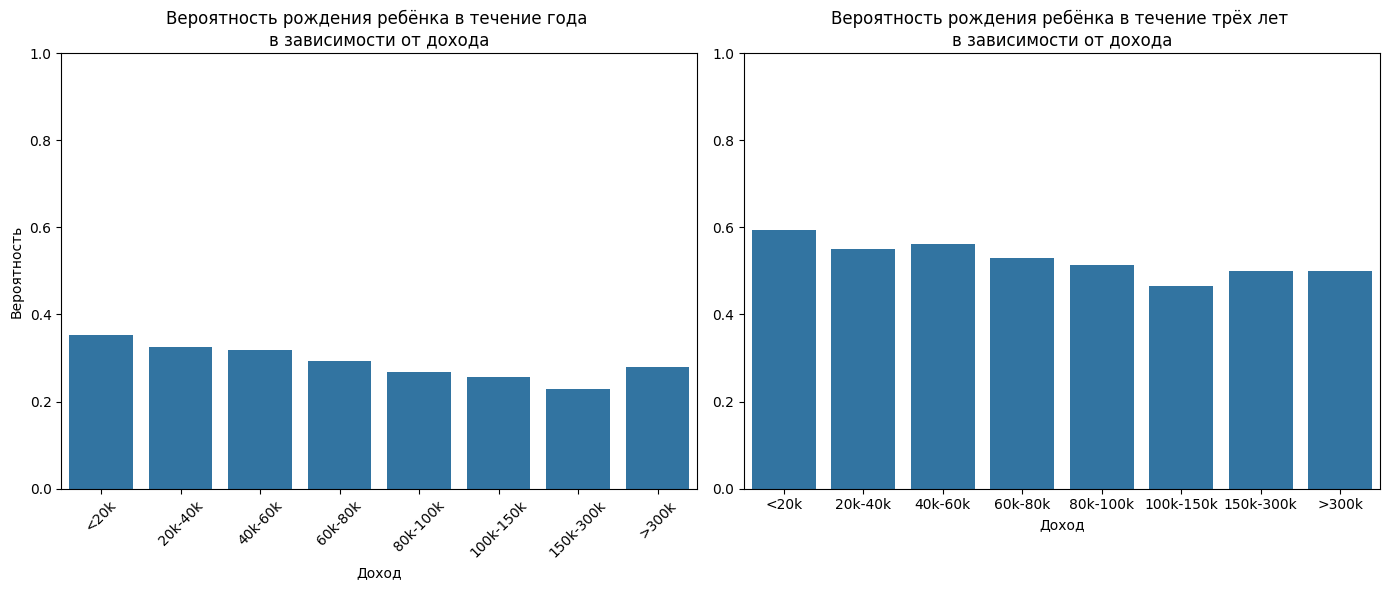


Вероятность рождения ребёнка в течение года в зависимости от дохода:
       Доход  Вероятность (1 год)
0       <20k             0.352257
1    20k-40k             0.325103
2    40k-60k             0.317766
3    60k-80k             0.292579
4   80k-100k             0.268380
5  100k-150k             0.255747
6  150k-300k             0.229345
7      >300k             0.278481

Вероятность рождения ребёнка в течение трёх лет в зависимости от дохода:
       Доход  Вероятность (3 года)
0       <20k              0.593233
1    20k-40k              0.551199
2    40k-60k              0.561198
3    60k-80k              0.530320
4   80k-100k              0.514039
5  100k-150k              0.465066
6  150k-300k              0.500000
7      >300k              0.500000


In [ ]:
# Визуализация
plt.figure(figsize=(14, 6))

#Вероятность за год
plt.subplot(1, 2, 1)
sns.barplot(data=rlms_prob_1, x='Доход', y='Вероятность (1 год)',
            order=['<20k', '20k-40k', '40k-60k', '60k-80k', '80k-100k', '100k-150k', '150k-300k', '>300k'])
plt.title('Вероятность рождения ребёнка в течение года \nв зависимости от дохода')
plt.xlabel('Доход')
plt.ylabel('Вероятность')
plt.xticks(rotation=45)
plt.ylim(0, 1)

#Вероятность за три года
plt.subplot(1, 2, 2)
sns.barplot(data=rlms_prob_3, x='Доход', y='Вероятность (3 года)',
            order=['<20k', '20k-40k', '40k-60k', '60k-80k', '80k-100k', '100k-150k', '150k-300k', '>300k'])
plt.title('Вероятность рождения ребёнка в течение трёх лет \nв зависимости от дохода')
plt.xlabel('Доход')
plt.ylabel('')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()
#Вывод численных результатов
print("\nВероятность рождения ребёнка в течение года в зависимости от дохода:")
print(rlms_prob_1)
print("\nВероятность рождения ребёнка в течение трёх лет в зависимости от дохода:")
print(rlms_prob_3)

### 3.3 Формулировка и проверка гипотез III

1. Изучите доступные в RLMS данные и сформулируйте три разные гипотезы о том, что может влиять на вероятность появления детей (помимо типа населённого пункта и дохода). При формулировке гипотез обязательно приведите ссылки на релевантные, актуальные и авторитетные источники (научные исследования по схожей проблематике на зарубежном статистическом материале).

2. Проверьте ваши гипотезы на данных. Для этого сформулируйте необходимые разрезы данных, рассчитайте статистики, визуализируйте (в виде графиков или таблиц) ваши расчёты. Сделайте вывод о том, как результаты соотносятся со сформулированными гипотезами.

3. Кратко охарактеризуйте результаты вашего исследования в рамках одного абзаца текста.

**Гипотеза 1: Женатые/замужние пары чаще заводят детей, чем пары, не состоящие в официальном браке.**

Источники:

1. Perelli-Harris B. How similar are cohabiting and married parents? Second conception risks by union type in the United States and across Europe //European Journal of Population. – 2014. – Т. 30. – №. 4. – С. 437-464.

Исследование анализирует, насколько тип партнёрского союза — официально зарегистрированный брак или сожительство — влияет на вероятность зачатия  второго ребёнка. Авторы рассматривают данные из США и нескольких европейских стран, включая страны Западной, Северной и Восточной Европы.
Сожительство связано с меньшей вероятностью рождения второго ребёнка, по сравнению с браком, особенно в странах, где сожительство считается менее стабильной формой отношений (например, в США и Восточной Европе).
В странах, где сожительство более институционализировано (например, Скандинавия), разница между сожителями и женатыми в плане рождения второго ребёнка менее выражена.

2. Zhang J., Song X. Fertility differences between married and cohabiting couples: A switching regression analysis. – IZA Discussion Papers, 2007. – №. 3245.

Исследование Института экономики труда (IZA) показало, что женатые пары имеют больше детей, чем сожительствующие. Основной причиной является то, что брак способствует специализации в домашнем хозяйстве, что увеличивает вероятность рождения детей.

3. O'Leary L. et al. Fertility and partnership status in the last two decades //Population Trends. – 2010. – Т. 140. – С. 5-35.

В статье  анализируются различия в фертильности в зависимости от семейного положения женщин. Женщины, состоящие в браке, демонстрируют более высокие показатели рождаемости по сравнению с сожительствующими и одинокими женщинами.


**Гипотеза 2: Женщины с высокой религиозной вовлечённостью чаще имеют детей, чем женщины с низким уровнем религиозности.**

Источники:
1. Frejka T., Westoff C. F. Religion, religiousness and fertility in the US and in Europe: Religion, religiosité et fécondité aux Etats-Unis et en Europe //European Journal of Population/Revue européenne de démographie. – 2008. – Т. 24. – С. 5-31.

В исследование подтверждается, что уровень рождаемости среди  религиозных женщин (по самооценке и частоте посещения религиозных служб) на 20–30% выше, чем среди нерелигиозных женщин.

2. Zhang L. Religious affiliation, religiosity, and male and female fertility //Demographic research. – 2008. – Т. 18. – С. 233-262.

Исследование анализирует влияние религиозной принадлежности и уровня религиозности на фертильность мужчин и женщин в США на основе данных Национального опроса роста семьи (NSFG).Женщины с высокой религиозной вовлечённостью имеют в среднем больше детей, чем женщины с низким уровнем религиозности или нерелигиозные.

3. Cranney S. The association between belief in god and fertility desires in Slovenia and the Czech Republic //Perspectives on sexual and reproductive health. – 2015. – Т. 47. – №. 2. – С. 83-89.

Исследование The association between belief in god and fertility desires in Slovenia and the Czech Republic Cranney S. в Словении и Чехии показало, что женщины, верящие в Бога, хотят иметь больше детей по сравнению с неверующими.

4. Peri-Rotem N. Religion and fertility in Western Europe: Trends across cohorts in Britain, France and the Netherlands //European Journal of population. – 2016. – Т. 32. – С. 231-265.

В исследование Peri-Rotem N.  "Religion and fertility in Western Europe: Trends across cohorts in Britain, France and the Netherlands" (2016) выявляется взаимосвязь между религиозностью и рождаемостью среди женщин в трёх западноевропейских странах (Великобритании, Франции и Нидерландов). Таким образом, практикующие религиозные женщины имеют более высокую фертильность по сравнению с нерелигиозными.



**Гипотеза 3: Удовлетворённость жизнью способствует появлению детей**

Источники

1.  Parr N. Satisfaction with life as an antecedent of fertility: Partner+ Happiness= Children? //Demographic research. – 2010. – Т. 22. – С. 635-662.

Авторы исследования обнаруживают положительную корреляцию между удовлетворенностью жизнью и вероятностью рождения детей. Удовлетворённость жизнью играет важную роль в принятии решения о рождении ребёнка, особенно при наличии других позитивных факторов (отношения, стабильность, поддержка близких).

2. Mencarini L. et al. Life satisfaction favors reproduction. The universal positive effect of life satisfaction on childbearing in contemporary low fertility countries //PloS one. – 2018. – Т. 13. – №. 12. – С. e0206202.

Исследование, опубликованное в PLoS ONE, анализирует данные из Австралии, Германии, России, Южной Кореи, Швейцарии, Великобритании и США. Результаты показали, что более высокий уровень субъективного благополучия связан с большей вероятностью рождения ребёнка во всех перечисленных странах.

3. Margolis R., Myrskylä M. A global perspective on happiness and fertility //Population and development review. – 2011. – Т. 37. – №. 1. – С. 29-56.

В статье анализируется взаимосвязь между субъективным благополучием (уровнем счастья) и фертильностью в разных странах, используя данные из World Values Survey и European Social Survey. В странах с низкой рождаемостью и высоким уровнем жизни, дети чаще появляются у тех, кто чувствует себя счастливым и удовлетворённым жизнью.



In [ ]:
# Заново считаем данные, только теперь будем собирать информацию по индивидам, а не по семьям
# Логика ввода аналогична вводу в начале работы
dfs = []
for i in range(23, 33):
    ch = waves[i - 23]
    """Открытие датасета"""
    try:
        df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_73.sav")
    except:
        try:
            df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_74.sav")
        except:
            try:
                df_i, _ = pt.read_sav(f"/content/Individuals/r{i}i_os_75.sav")
            except Exception as e:
                print(f"Ошибка загрузки: {e}")
    data = {
        "wave": [ch] * len(df_i),
        "num_child": df_i[f'{ch}j72.172'],
        "redid_i" : df_i[f'{ch}redid_i'],
        "id_h": df_i[f"{ch}id_h"],
        "married" : df_i[f"{ch}j322"],
        "life_satisfaction" : df_i[f"{ch}j65"],
        "religion" : df_i[f"{ch}j72.18"],
        "status":df_i["status"],
        "popul": df_i["popul"]
    }
    df_i = pd.DataFrame(data)
    dfs.append(df_i)
rlms_df_ind = pd.concat(dfs, axis=0, ignore_index=True)
print(rlms_df_ind)

       wave  num_child   redid_i        id_h  married  life_satisfaction  \
0         s        3.0  169501.0     10012.0      5.0                2.0   
1         s        NaN  169101.0     10003.0      1.0                2.0   
2         s        2.0  169201.0     10004.0      3.0                3.0   
3         s        3.0  170101.0     10024.0      3.0                5.0   
4         s        1.0  170102.0     10024.0      2.0                5.0   
...     ...        ...       ...         ...      ...                ...   
122937   bb        3.0  660907.0  13890024.0      5.0                2.0   
122938   bb        NaN  663004.0  14230185.0      1.0                1.0   
122939   bb        NaN  665601.0   1350669.0      1.0                2.0   
122940   bb        2.0  666101.0   1357046.0      3.0                2.0   
122941   bb        2.0  665801.0   1350890.0      5.0                4.0   

        religion  status       popul  
0            1.0     3.0     12200.0  
1        

In [ ]:
rlms_df_ind = rlms_df_ind.rename(columns=lambda x: x.strip().lower())
rlms_df_ind.head()

,wave,num_child,redid_i,id_h,married,life_satisfaction,religion,status,popul
0,s,3.0,169501.0,10012.0,5.0,2.0,1.0,3.0,12200.0
1,s,NaN,169101.0,10003.0,1.0,2.0,2.0,3.0,12200.0
2,s,2.0,169201.0,10004.0,3.0,3.0,2.0,3.0,12200.0
3,s,3.0,170101.0,10024.0,3.0,5.0,2.0,3.0,12200.0
4,s,1.0,170102.0,10024.0,2.0,5.0,2.0,3.0,12200.0


In [ ]:
def harmonize_data_ind(data):
    df = data.copy()
    """Функция для предварительной обработки данных RLMS."""
    df = df.rename(columns=lambda x: x.strip().lower())
    df = df.dropna(subset=["num_child"])
    df = df.drop(df[df["num_child"] > 9000].index)
    status_map = {1: "Областной центр", 2: "Город", 3: "ПГТ", 4: "Село"}
    wave_to_year = {
        "s": 2014,
        "t": 2015,
        "u": 2016,
        "v": 2017,
        "w": 2018,
        "x": 2019,
        "y": 2020,
        "z": 2021,
        "aa": 2022,
        "bb": 2023,
    }
    df["status"] = df["status"].map(status_map)
    df["redid_i"] = df["redid_i"].astype(int)
    df["religion"] = df["religion"].apply(
        lambda x: (
            "Верующий"
            if x in [1, 2]
            else "Неверующий" if x in [3, 4, 5] else "Нет репрезентативного ответа"
        )
    )

    df["life_satisfaction"] = df["life_satisfaction"].apply(
        lambda x: (
            "Доволен"
            if x in [1, 2]
            else "Недоволен" if x in [4, 5] else "Нет репрезентативного ответа"
        )
    )
    df["married"] = df["married"].apply(
        lambda x: (
            "Когда-либо был в браке"
            if x in [2, 3, 4, 5, 6]
            else (
                "Никогда не был в браке" if x in [1] else "Нет репрезентативного ответа"
            )
        )
    )
    df["wave"] = df["wave"].map(wave_to_year).astype(int)
    df["id_h"] = df["id_h"].astype(int)
    df["num_child"] = df["num_child"].astype(int)
    return df

In [ ]:
rlms_ind_clear = harmonize_data_ind(rlms_df_ind)
rlms_ind_clear.head()
print(rlms_ind_clear)
children_ind = dict()  # Словарь: номер индивида - количество детей
answer_ind = set()  # Номера людей, у которых родился ребёнок
ids_ind = set()  # Множество всех людей


def identify_new_children_ind(df):
    """Функция для идентификации индивидов, у которых появились новые дети."""
    for _, row in df.iterrows():
        ids_ind.add(row["redid_i"])
        if row["redid_i"] in children_ind.keys():
            if row["num_child"] > children_ind[row["redid_i"]]:
                answer_ind.add(row["redid_i"])
        else:
            children_ind[row["redid_i"]] = row["num_child"]


identify_new_children_ind(rlms_ind_clear.copy())
print("Количество людей, в которых родился ребёнок:", len(answer_ind))
print("Всего людей:", len(ids_ind))

        wave  num_child  redid_i      id_h                 married  \
0       2014          3   169501     10012  Когда-либо был в браке   
2       2014          2   169201     10004  Когда-либо был в браке   
3       2014          3   170101     10024  Когда-либо был в браке   
4       2014          1   170102     10024  Когда-либо был в браке   
5       2014          2   171602     10047  Когда-либо был в браке   
...      ...        ...      ...       ...                     ...   
122931  2023          1   651004  13815081  Когда-либо был в браке   
122936  2023          2   569601  13860043  Когда-либо был в браке   
122937  2023          3   660907  13890024  Когда-либо был в браке   
122940  2023          2   666101   1357046  Когда-либо был в браке   
122941  2023          2   665801   1350890  Когда-либо был в браке   

                   life_satisfaction    religion           status       popul  
0                            Доволен    Верующий              ПГТ     12200.0  

In [ ]:
# Сохраняем в датасет последнюю информацию о каждом индивиде
# Логика аналогична сохранению последней информации о каждой семье
rlms_final_ind = pd.DataFrame(
    {
        "wave": [],
        "redid_i": [],
        "num_child": [],
        "born_child": [],
        "married": [],
        "status": [],
        "popul": [],
        "life_satisfaction": [],
        "religion": [],
    }
)

used_ids_ind = set()
for i, row in rlms_ind_clear[::-1].iterrows():
    if row["redid_i"] not in used_ids_ind:
        rlms_final_ind.loc[len(rlms_final_ind)] = [
            row["wave"],
            row["redid_i"],
            row["num_child"],
            int(row["redid_i"] in answer_ind),
            row["married"],
            row["status"],
            row["popul"],
            row["life_satisfaction"],
            row["religion"],
        ]
        used_ids_ind.add(row["redid_i"])
rlms_final_ind = rlms_final_ind[::-1]
print(rlms_final_ind)

       wave  redid_i  num_child  born_child                 married  \
27040  2014   174703          1           0  Когда-либо был в браке   
27039  2014   174704          1           0  Когда-либо был в браке   
27038  2014   177103          1           0  Когда-либо был в браке   
27037  2014   313303          2           0  Когда-либо был в браке   
27036  2014   326304          2           0  Когда-либо был в браке   
...     ...      ...        ...         ...                     ...   
4      2023   651004          1           0  Когда-либо был в браке   
3      2023   569601          2           0  Когда-либо был в браке   
2      2023   660907          3           0  Когда-либо был в браке   
1      2023   666101          2           1  Когда-либо был в браке   
0      2023   665801          2           0  Когда-либо был в браке   

                status       popul             life_satisfaction    religion  
27040             Село      2100.0  Нет репрезентативного ответа  Не

In [ ]:
def calculate_new_children_share_ind(data):
    """
    Рассчитывает долю индивидов с новыми детьми по:
    - брачному статусу (married)
    - религиозности (religion)
    - удовлетворённости жизнью (life_satisfaction)
    """
    # Фильтруем только релевантные категории (исключаем "Нет репрезентативного ответа")
    filtered_data = data[
        (data['married'].isin(['Когда-либо был в браке', 'Никогда не был в браке'])) &
        (data['religion'].isin(['Верующий', 'Неверующий'])) &
        (data['life_satisfaction'].isin(['Доволен', 'Недоволен']))
    ].copy()

    # Доли по брачному статусу
    married_stats = (
        filtered_data.groupby('married')['born_child']
        .mean()
        .rename('share')
        .reset_index()
    )

    # Доли по религиозности
    religion_stats = (
        filtered_data.groupby('religion')['born_child']
        .mean()
        .rename('share')
        .reset_index()
    )

    # Доли по удовлетворённости жизнью
    satisfaction_stats = (
        filtered_data.groupby('life_satisfaction')['born_child']
        .mean()
        .rename('share')
        .reset_index()
    )

    return {
        'married': married_stats,
        'religion': religion_stats,
        'life_satisfaction': satisfaction_stats
    }

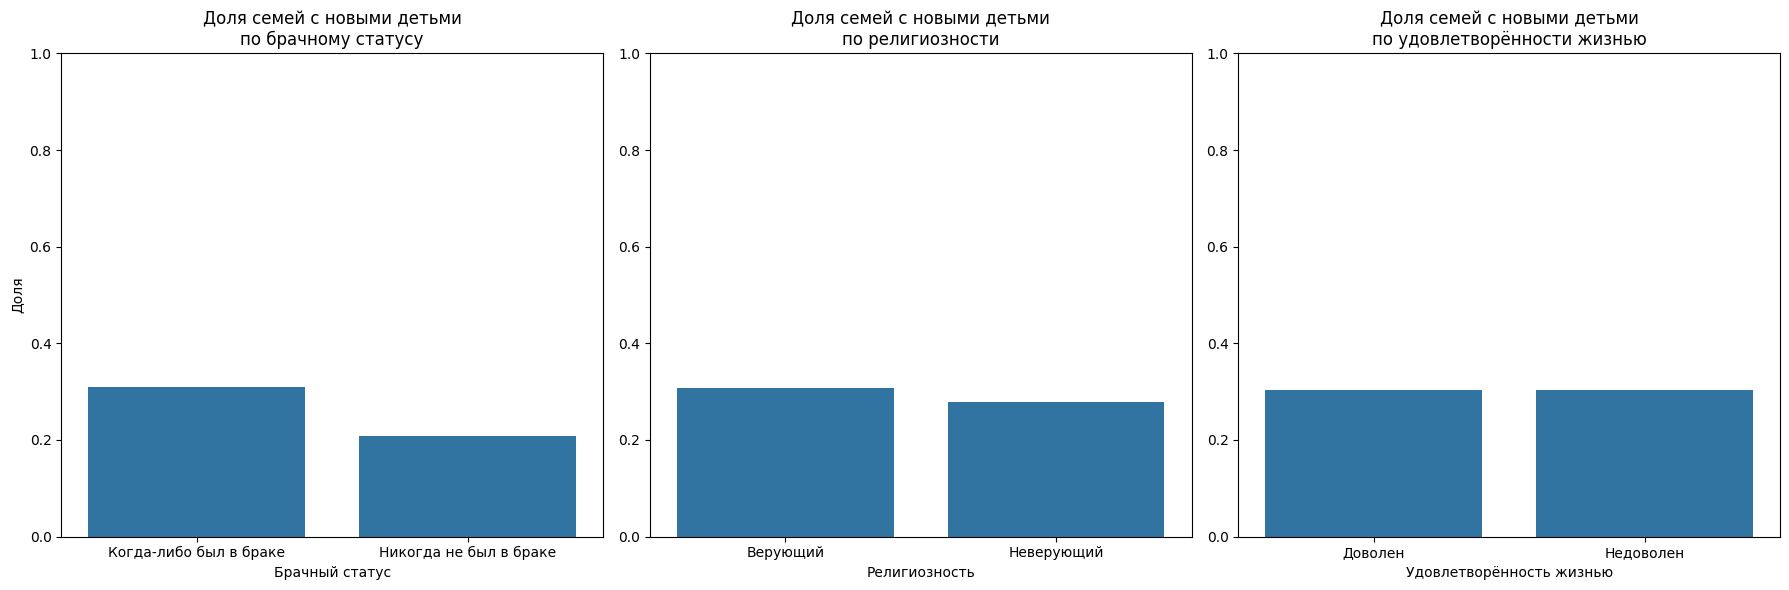

Доля по брачному статусу:
                  married     share
0  Когда-либо был в браке  0.308869
1  Никогда не был в браке  0.208188

Доля по религиозности:
     religion     share
0    Верующий  0.308224
1  Неверующий  0.279305

Доля по удовлетворённости жизнью:
  life_satisfaction     share
0           Доволен  0.302662
1         Недоволен  0.303420


In [ ]:
stats = calculate_new_children_share_ind(rlms_final_ind)

# Визуализация
plt.figure(figsize=(18, 6))

# График по брачному статусу
plt.subplot(1, 3, 1)
sns.barplot(
    data=stats['married'],
    x='married',
    y='share',
    order=['Когда-либо был в браке', 'Никогда не был в браке']
)
plt.title('Доля семей с новыми детьми\nпо брачному статусу')
plt.xlabel('Брачный статус')
plt.ylabel('Доля')
plt.ylim(0, 1)

# График по религиозности
plt.subplot(1, 3, 2)
sns.barplot(
    data=stats['religion'],
    x='religion',
    y='share',
    order=['Верующий', 'Неверующий']
)
plt.title('Доля семей с новыми детьми\nпо религиозности')
plt.xlabel('Религиозность')
plt.ylabel('')
plt.ylim(0, 1)

# График по удовлетворённости жизнью
plt.subplot(1, 3, 3)
sns.barplot(
    data=stats['life_satisfaction'],
    x='life_satisfaction',
    y='share',
    order=['Доволен', 'Недоволен']
)
plt.title('Доля семей с новыми детьми\nпо удовлетворённости жизнью')
plt.xlabel('Удовлетворённость жизнью')
plt.ylabel('')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

# Вывод численных результатов
print("Доля по брачному статусу:")
print(stats['married'])
print("\nДоля по религиозности:")
print(stats['religion'])
print("\nДоля по удовлетворённости жизнью:")
print(stats['life_satisfaction'])

**Гипотеза 1:**
По данным RLMS доля индивидов с новыми детьми выше среди состоящих в браке, что подтверждает нашу гипотезу.

**Гипотеза 2:**
Нельзя точно сказать, подтверждается ли гипотеза о положительном влиянии религиозности на вероятность рождения детей на наших данных. Доля индивидов с новыми детьми среди верующих выше, чем среди неверующих, но разница незначительная

**Гипотеза 3:**
Гипотеза не подтверждается на нашей выборке: различия между группами "доволен" и "недоволен" крайне малы и статистически, скорее всего, незначимы.

**Выводы:**

Работать с данными RLMS было по-настоящему увлекательно. Опираясь на эти данные, мы смогли проверить выдвинутые нами гипотезы, и ни одна не дала нам противоречия: гипотеза 1 подтвердилась; тенденция гипотезы 2 тоже соблюдена, но разница в долях незначительная, поэтому нельзя точно сказать о ее подтверждении; гипотеза 3 не подтвердилась, но и обратное сказать нельзя, так как различия долей крайне малы.